In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [8]:
df=pd.read_csv(r"C:\Users\acces\Saved Games\Downloads\googleplaystore.csv")

In [9]:
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [11]:
df.shape

(10841, 13)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB


# SUMMARY OF DATASET


In [16]:
df.describe()

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


In [17]:
df.isna().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

# INSIGHTS AND OBSERVATIONS
The dataset has missing values.
Highest in the Rating column.

In [41]:
df_copy=df.copy()

In [19]:
df_copy.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up


# DATA CLEANING

In [ ]:
## COLUMN REVIEWS

In [20]:
df_copy['Reviews'].unique()

<ArrowStringArray>
[   '159',    '967',  '87510', '215644',    '167',    '178',  '36815',
  '13791',    '121',  '13880',
 ...
   '2036',  '56496', '376223',    '785',   '5775',    '885',  '88486',
    '603',   '1195', '398307']
Length: 6002, dtype: str

In [42]:
df_copy['Reviews'].str.isnumeric().sum()

np.int64(10840)

In [27]:
~df_copy['Reviews'].str.isnumeric().sum()

np.int64(-10841)

In [31]:
df_copy[~df_copy['Reviews'].str.isnumeric()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [43]:
## DROP THE ROW 10472

df_copy=df_copy.drop(df_copy.index[10472])

In [35]:
df_copy[~df_copy['Reviews'].str.isnumeric()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [44]:
## CONVERT REVIEWS DATATYPE TO INT

df_copy['Reviews']=df_copy['Reviews'].astype(int)

In [46]:
df_copy.info()

<class 'pandas.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  str    
 1   Category        10840 non-null  str    
 2   Rating          9366 non-null   float64
 3   Reviews         10840 non-null  int64  
 4   Size            10840 non-null  str    
 5   Installs        10840 non-null  str    
 6   Type            10839 non-null  str    
 7   Price           10840 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10840 non-null  str    
 10  Last Updated    10840 non-null  str    
 11  Current Ver     10832 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), int64(1), str(11)
memory usage: 2.2 MB


In [47]:
## COLUMN SIZE

In [48]:
df_copy['Size'].unique()

<ArrowStringArray>
[  '19M',   '14M',  '8.7M',   '25M',  '2.8M',  '5.6M',   '29M',   '33M',
  '3.1M',   '28M',
 ...
  '467k',  '157k',   '44k',  '676k',   '67k',  '552k',  '885k', '1020k',
  '582k',  '619k']
Length: 461, dtype: str

In [64]:
## 1000 k = 1 million

df_copy['Size']=df_copy['Size'].str.replace('M', '000')
df_copy['Size']=df_copy['Size'].str.replace('k',' ')

In [54]:
df_copy['Size']

0                     19000
1                     14000
2                    8.7000
3                     25000
4                    2.8000
                ...        
10836                 53000
10837                3.6000
10838                9.5000
10839    Varies with device
10840                 19000
Name: Size, Length: 10840, dtype: str

In [65]:
df_copy.loc[df_copy['Size'].astype(str).str.contains(r'[A-Za-z]',na=False)]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
37,Floor Plan Creator,ART_AND_DESIGN,4.1,36639,Varies with device,"5,000,000+",Free,0,Everyone,Art & Design,"July 14, 2018",Varies with device,2.3.3 and up
42,Textgram - write on photos,ART_AND_DESIGN,4.4,295221,Varies with device,"10,000,000+",Free,0,Everyone,Art & Design,"July 30, 2018",Varies with device,Varies with device
52,Used Cars and Trucks for Sale,AUTO_AND_VEHICLES,4.6,17057,Varies with device,"1,000,000+",Free,0,Everyone,Auto & Vehicles,"July 30, 2018",Varies with device,Varies with device
67,Ulysse Speedometer,AUTO_AND_VEHICLES,4.3,40211,Varies with device,"5,000,000+",Free,0,Everyone,Auto & Vehicles,"July 30, 2018",Varies with device,Varies with device
68,REPUVE,AUTO_AND_VEHICLES,3.9,356,Varies with device,"100,000+",Free,0,Everyone,Auto & Vehicles,"May 25, 2018",Varies with device,Varies with device
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10713,My Earthquake Alerts - US & Worldwide Earthquakes,WEATHER,4.4,3471,Varies with device,"100,000+",Free,0,Everyone,Weather,"July 24, 2018",Varies with device,Varies with device
10725,Posta App,MAPS_AND_NAVIGATION,3.6,8,Varies with device,"1,000+",Free,0,Everyone,Maps & Navigation,"September 27, 2017",Varies with device,4.4 and up
10765,Chat For Strangers - Video Chat,SOCIAL,3.4,622,Varies with device,"100,000+",Free,0,Mature 17+,Social,"May 23, 2018",Varies with device,Varies with device
10826,Frim: get new friends on local chat rooms,SOCIAL,4.0,88486,Varies with device,"5,000,000+",Free,0,Mature 17+,Social,"March 23, 2018",Varies with device,Varies with device


In [71]:
df_copy['Size']=df_copy['Size'].replace('Varies with device', np.nan)

In [72]:
df_copy['Size'].astype(str).str.contains(r'[A-Za-z]',na=False).sum()

np.int64(0)

In [78]:
## CONVERT SIZE TO FLOAT

df_copy['Size']=df_copy['Size'].astype(float)

In [76]:
df_copy.isna().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size              1695
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64

In [80]:
df_copy['Size']

0        19000.0
1        14000.0
2            8.7
3        25000.0
4            2.8
          ...   
10836    53000.0
10837        3.6
10838        9.5
10839        NaN
10840    19000.0
Name: Size, Length: 10840, dtype: float64

In [81]:
## COLUMN Installs and Price

In [82]:
df_copy['Installs'].unique()

<ArrowStringArray>
[       '10,000+',       '500,000+',     '5,000,000+',    '50,000,000+',
       '100,000+',        '50,000+',     '1,000,000+',    '10,000,000+',
         '5,000+',   '100,000,000+', '1,000,000,000+',         '1,000+',
   '500,000,000+',            '50+',           '100+',           '500+',
            '10+',             '1+',             '5+',             '0+',
              '0']
Length: 21, dtype: str

In [83]:
df_copy['Price'].unique()

<ArrowStringArray>
[      '0',   '$4.99',   '$3.99',   '$6.99',   '$1.49',   '$2.99',   '$7.99',
   '$5.99',   '$3.49',   '$1.99',   '$9.99',   '$7.49',   '$0.99',   '$9.00',
   '$5.49',  '$10.00',  '$24.99',  '$11.99',  '$79.99',  '$16.99',  '$14.99',
   '$1.00',  '$29.99',  '$12.99',   '$2.49',  '$10.99',   '$1.50',  '$19.99',
  '$15.99',  '$33.99',  '$74.99',  '$39.99',   '$3.95',   '$4.49',   '$1.70',
   '$8.99',   '$2.00',   '$3.88',  '$25.99', '$399.99',  '$17.99', '$400.00',
   '$3.02',   '$1.76',   '$4.84',   '$4.77',   '$1.61',   '$2.50',   '$1.59',
   '$6.49',   '$1.29',   '$5.00',  '$13.99', '$299.99', '$379.99',  '$37.99',
  '$18.99', '$389.99',  '$19.90',   '$8.49',   '$1.75',  '$14.00',   '$4.85',
  '$46.99', '$109.99', '$154.99',   '$3.08',   '$2.59',   '$4.80',   '$1.96',
  '$19.40',   '$3.90',   '$4.59',  '$15.46',   '$3.04',   '$4.29',   '$2.60',
   '$3.28',   '$4.60',  '$28.99',   '$2.95',   '$2.90',   '$1.97', '$200.00',
  '$89.99',   '$2.56',  '$30.99',   '$3.61', 

In [84]:
spcl_chars = ['$','+',',']
cols = ['Installs','Price']
for i in spcl_chars:
    for x in cols:
        df_copy[x]=df_copy[x].str.replace(i, '')

In [85]:
df_copy['Installs'].unique()

<ArrowStringArray>
[     '10000',     '500000',    '5000000',   '50000000',     '100000',
      '50000',    '1000000',   '10000000',       '5000',  '100000000',
 '1000000000',       '1000',  '500000000',         '50',        '100',
        '500',         '10',          '1',          '5',          '0']
Length: 20, dtype: str

In [86]:
df_copy['Price'].unique()

<ArrowStringArray>
[     '0',   '4.99',   '3.99',   '6.99',   '1.49',   '2.99',   '7.99',
   '5.99',   '3.49',   '1.99',   '9.99',   '7.49',   '0.99',   '9.00',
   '5.49',  '10.00',  '24.99',  '11.99',  '79.99',  '16.99',  '14.99',
   '1.00',  '29.99',  '12.99',   '2.49',  '10.99',   '1.50',  '19.99',
  '15.99',  '33.99',  '74.99',  '39.99',   '3.95',   '4.49',   '1.70',
   '8.99',   '2.00',   '3.88',  '25.99', '399.99',  '17.99', '400.00',
   '3.02',   '1.76',   '4.84',   '4.77',   '1.61',   '2.50',   '1.59',
   '6.49',   '1.29',   '5.00',  '13.99', '299.99', '379.99',  '37.99',
  '18.99', '389.99',  '19.90',   '8.49',   '1.75',  '14.00',   '4.85',
  '46.99', '109.99', '154.99',   '3.08',   '2.59',   '4.80',   '1.96',
  '19.40',   '3.90',   '4.59',  '15.46',   '3.04',   '4.29',   '2.60',
   '3.28',   '4.60',  '28.99',   '2.95',   '2.90',   '1.97', '200.00',
  '89.99',   '2.56',  '30.99',   '3.61', '394.99',   '1.26',   '1.20',
   '1.04']
Length: 92, dtype: str

In [88]:
df_copy['Installs']=df_copy['Installs'].astype(int)


In [89]:
df_copy['Price']=df_copy['Price'].astype(float)

In [90]:
df_copy.info()

<class 'pandas.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  str    
 1   Category        10840 non-null  str    
 2   Rating          9366 non-null   float64
 3   Reviews         10840 non-null  int64  
 4   Size            9145 non-null   float64
 5   Installs        10840 non-null  int64  
 6   Type            10839 non-null  str    
 7   Price           10840 non-null  float64
 8   Content Rating  10840 non-null  str    
 9   Genres          10840 non-null  str    
 10  Last Updated    10840 non-null  str    
 11  Current Ver     10832 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(3), int64(2), str(8)
memory usage: 2.1 MB


In [91]:
## COLUMN LAST UPDATED

In [92]:
df_copy['Last Updated'].unique()

<ArrowStringArray>
[   'January 7, 2018',   'January 15, 2018',     'August 1, 2018',
       'June 8, 2018',      'June 20, 2018',     'March 26, 2017',
     'April 26, 2018',      'June 14, 2018', 'September 20, 2017',
       'July 3, 2018',
 ...
  'November 23, 2015',      'June 17, 2012',  'February 27, 2015',
  'December 18, 2013',   'February 6, 2012',  'November 25, 2014',
       'May 19, 2016',   'January 20, 2014',  'February 16, 2014',
     'March 23, 2014']
Length: 1377, dtype: str

In [94]:
df_copy['Last Updated']=pd.to_datetime(df_copy['Last Updated'],dayfirst=False)

In [98]:
df_copy['Year']=df_copy['Last Updated'].dt.year
df_copy['Month']=df_copy['Last Updated'].dt.month
df_copy['Day']=df_copy['Last Updated'].dt.day

In [99]:
df_copy.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Year,Month,Day
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19000.0,10000,Free,0.0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,2018,1,7
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14000.0,500000,Free,0.0,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up,2018,1,15


In [100]:
df_copy.drop('Last Updated',axis=1,inplace=True)

In [101]:
df_copy.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Current Ver,Android Ver,Year,Month,Day
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19000.0,10000,Free,0.0,Everyone,Art & Design,1.0.0,4.0.3 and up,2018,1,7
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14000.0,500000,Free,0.0,Everyone,Art & Design;Pretend Play,2.0.0,4.0.3 and up,2018,1,15


In [102]:
df_copy.info()

<class 'pandas.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  str    
 1   Category        10840 non-null  str    
 2   Rating          9366 non-null   float64
 3   Reviews         10840 non-null  int64  
 4   Size            9145 non-null   float64
 5   Installs        10840 non-null  int64  
 6   Type            10839 non-null  str    
 7   Price           10840 non-null  float64
 8   Content Rating  10840 non-null  str    
 9   Genres          10840 non-null  str    
 10  Current Ver     10832 non-null  str    
 11  Android Ver     10838 non-null  str    
 12  Year            10840 non-null  int32  
 13  Month           10840 non-null  int32  
 14  Day             10840 non-null  int32  
dtypes: float64(3), int32(3), int64(2), str(7)
memory usage: 2.0 MB


In [105]:
## HANDLING DUPLICATES

df_copy.duplicated().sum()

np.int64(483)

In [109]:
df_copy=df_copy.drop_duplicates()

In [110]:
df_copy.duplicated().sum()

np.int64(0)

In [111]:
## HANDLING MISSING VALUES

df_copy.isna().sum()

App                  0
Category             0
Rating            1465
Reviews              0
Size              1526
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Current Ver          8
Android Ver          2
Year                 0
Month                0
Day                  0
dtype: int64

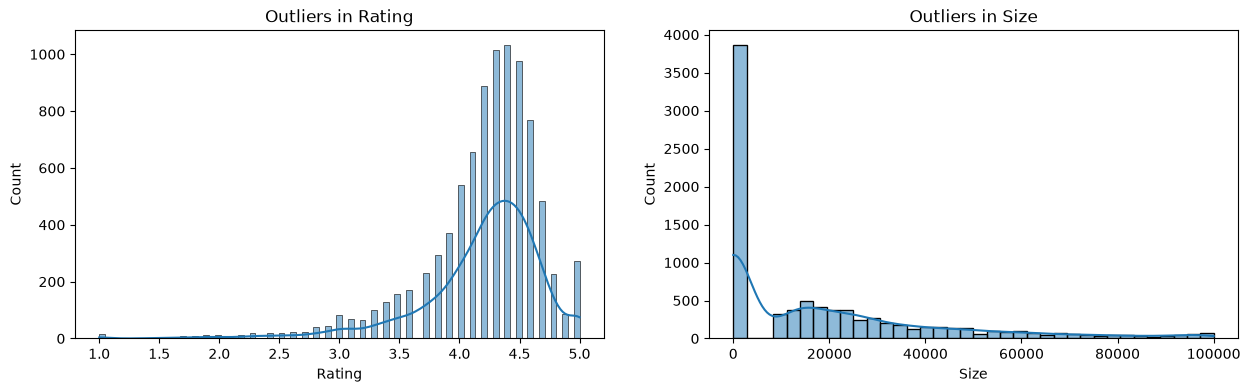

In [122]:
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
sns.histplot(x='Rating',data=df_copy,kde=True)
plt.xlabel('Rating')
plt.tight_layout
plt.title('Outliers in Rating')

plt.subplot(1,2,2)
sns.histplot(x='Size',data=df_copy,kde=True)
plt.xlabel('Size')
plt.tight_layout
plt.title('Outliers in Size')
plt.show()

# EDA
### OBSERVATIONS ON OUTLIERS
Rating and Size, both of thsoe columns have outliers, hence the Median imputation would be used to fill the nulls.

In [127]:
(df_copy['Rating'].isna().mean()*100).round(2)

np.float64(14.15)

In [128]:
(df_copy['Size'].isna().mean()*100).round(2)

np.float64(14.73)

In [135]:
df_copy['Rating']=df_copy['Rating'].fillna(df_copy['Rating'].median())

In [136]:
df_copy['Rating'].isna().sum()

np.int64(0)

In [137]:
df_copy['Size']=df_copy['Size'].fillna(df_copy['Size'].median())

In [139]:
df_copy['Size'].isna().sum()

np.int64(0)

In [146]:
## DROPPING NULL ROWS

In [140]:
df_copy.isna().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              1
Price             0
Content Rating    0
Genres            0
Current Ver       8
Android Ver       2
Year              0
Month             0
Day               0
dtype: int64

In [144]:
df_copy=df_copy.dropna(subset=['Type','Android Ver'])

In [145]:
df_copy.isna().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Current Ver       8
Android Ver       0
Year              0
Month             0
Day               0
dtype: int64

In [147]:
df_copy.info()

<class 'pandas.DataFrame'>
Index: 10354 entries, 0 to 10840
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10354 non-null  str    
 1   Category        10354 non-null  str    
 2   Rating          10354 non-null  float64
 3   Reviews         10354 non-null  int64  
 4   Size            10354 non-null  float64
 5   Installs        10354 non-null  int64  
 6   Type            10354 non-null  str    
 7   Price           10354 non-null  float64
 8   Content Rating  10354 non-null  str    
 9   Genres          10354 non-null  str    
 10  Current Ver     10346 non-null  str    
 11  Android Ver     10354 non-null  str    
 12  Year            10354 non-null  int32  
 13  Month           10354 non-null  int32  
 14  Day             10354 non-null  int32  
dtypes: float64(3), int32(3), int64(2), str(7)
memory usage: 1.9 MB


In [149]:
df_copy.shape

(10354, 15)

In [150]:
df_copy.describe()

,Rating,Reviews,Size,Installs,Price,Year,Month,Day
count,10354.000000,1.035400e+04,10354.000000,1.035400e+04,10354.000000,10354.000000,10354.000000,10354.000000
mean,4.203680,4.060222e+05,18393.638449,1.416186e+07,1.030955,2017.382751,6.397334,15.616380
std,0.485651,2.697160e+06,22274.632858,8.025082e+07,16.280977,1.112878,2.606513,9.528507
min,1.000000,0.000000e+00,1.000000,0.000000e+00,0.000000,2010.000000,1.000000,1.000000
25%,4.100000,3.200000e+01,6.600000,1.000000e+03,0.000000,2017.000000,5.000000,6.000000
50%,4.300000,1.686000e+03,13000.000000,1.000000e+05,0.000000,2018.000000,7.000000,16.000000
75%,4.500000,4.648275e+04,26000.000000,1.000000e+06,0.000000,2018.000000,8.000000,24.000000
max,5.000000,7.815831e+07,100000.000000,1.000000e+09,400.000000,2018.000000,12.000000,31.000000


In [151]:
df_copy['Rating'].median()

np.float64(4.3)

In [152]:
df_copy['Size'].median()

np.float64(13000.0)

In [153]:
df_copy['Size'].skew()

np.float64(1.6182743815827212)

In [154]:
df_copy['Rating'].skew()

np.float64(-2.0447246367472536)

# EDA ANALYSIS

In [159]:
numerical_features = [x for x in df_copy.columns if df_copy[x].dtype != 'str']
categorical_features = [y for y in df_copy.columns if df_copy[y].dtype == 'str']

print("We have {} numerical_features : {}".format(len(numerical_features),numerical_features))
print("\nWe have {} categorical_features : {}".format(len(categorical_features),categorical_features))

We have 8 numerical_features : ['Rating', 'Reviews', 'Size', 'Installs', 'Price', 'Year', 'Month', 'Day']

We have 7 categorical_features : ['App', 'Category', 'Type', 'Content Rating', 'Genres', 'Current Ver', 'Android Ver']


## Feature Information
1. App :- Name of the App
2. Category :- Category under which the App falls.
3. Rating :- Application's rating on playstore
4. Reviews :- Number of reviews of the App.
5. Size :- Size of the App.
6. Install :- Number of Installs of the App
7. Type :- If the App is free/paid
8. Price :- Price of the app (0 if it is Free)
9. Content Rating :- Appropiate Target Audience of the App.
10. Genres:- Genre under which the App falls.
11. Last Updated :- Date when the App was last updated(dropped) for year,month,day
12. Current Ver :- Current Version of the Application
13. Android Ver :- Minimum Android Version required to run the App

In [167]:
## PROPORTION OF COUNT DATA ON CATEGORICAL COLUMNS

for cols in categorical_features:
    print(df_copy[cols].value_counts(normalize=True)*100)
    print("*" * 70)

App
ROBLOX                                           0.086923
8 Ball Pool                                      0.067607
Bubble Shooter                                   0.057949
Helix Jump                                       0.057949
Zombie Catchers                                  0.057949
                                                   ...   
Sya9a Maroc - FR                                 0.009658
Fr. Mike Schmitz Audio Teachings                 0.009658
Parkinson Exercices FR                           0.009658
The SCP Foundation DB fr nn5n                    0.009658
iHoroscope - 2018 Daily Horoscope & Astrology    0.009658
Name: proportion, Length: 9656, dtype: float64
**********************************************************************
Category
FAMILY                 18.756036
GAME                   10.826734
TOOLS                   8.141781
BUSINESS                4.124010
MEDICAL                 3.940506
PRODUCTIVITY            3.930848
PERSONALIZATION         3.728028


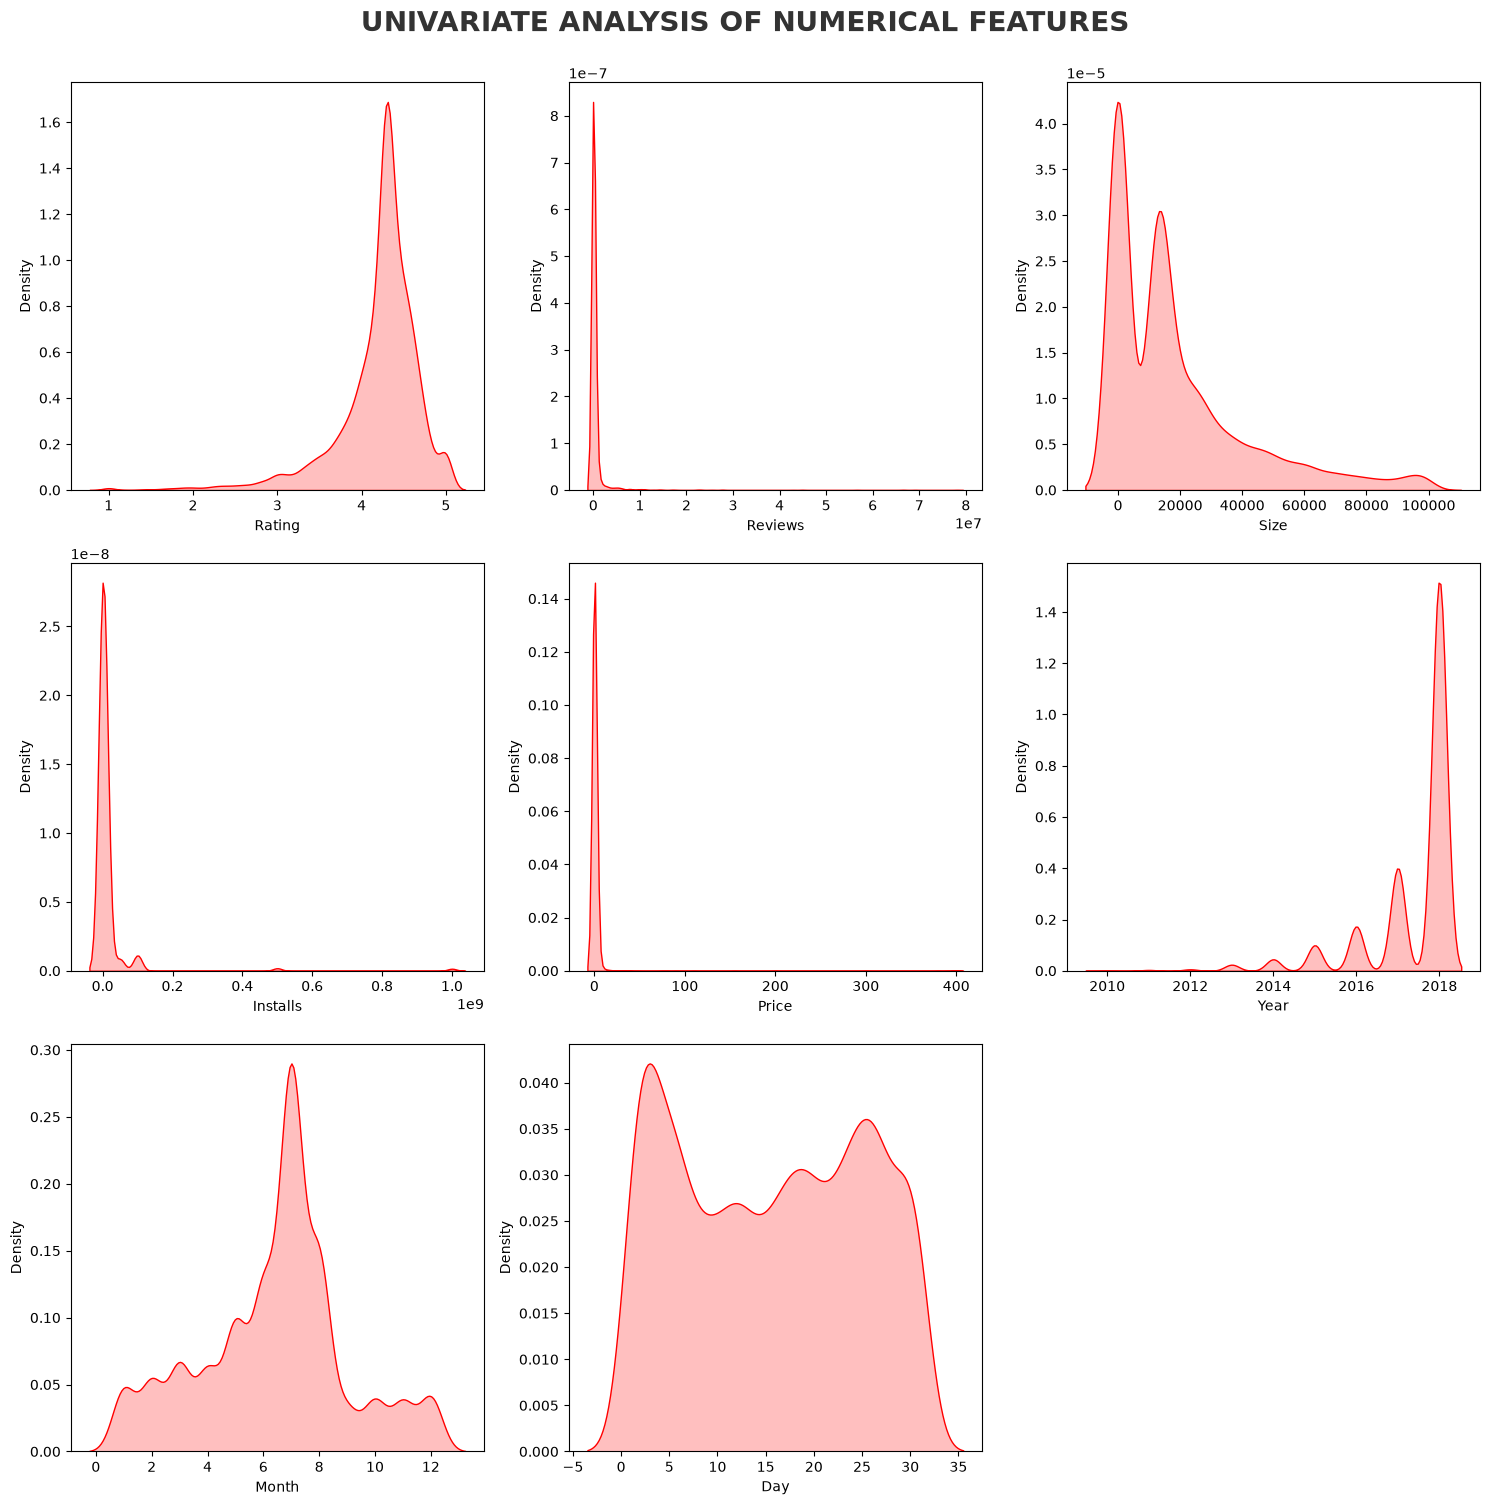

In [168]:
## PROPORTION OF COUNT DATA ON NUMERICAL FEATURES

plt.figure(figsize=(15,15))
plt.suptitle("UNIVARIATE ANALYSIS OF NUMERICAL FEATURES",fontsize=20, fontweight='bold',alpha=0.8,y=1)

for i in range(0,len(numerical_features)):
    plt.subplot(3,3,i+1)
    sns.kdeplot(x=df_copy[numerical_features[i]], shade=True, color='r')
    plt.xlabel(numerical_features[i])
    plt.tight_layout()

## OBSERVATIONS PERTAINING TO UNIVARIATE NUMERICAL ANALYSIS

Rating and Year are left skewed.
Reviews, Size, Installs, Price are right skewed.

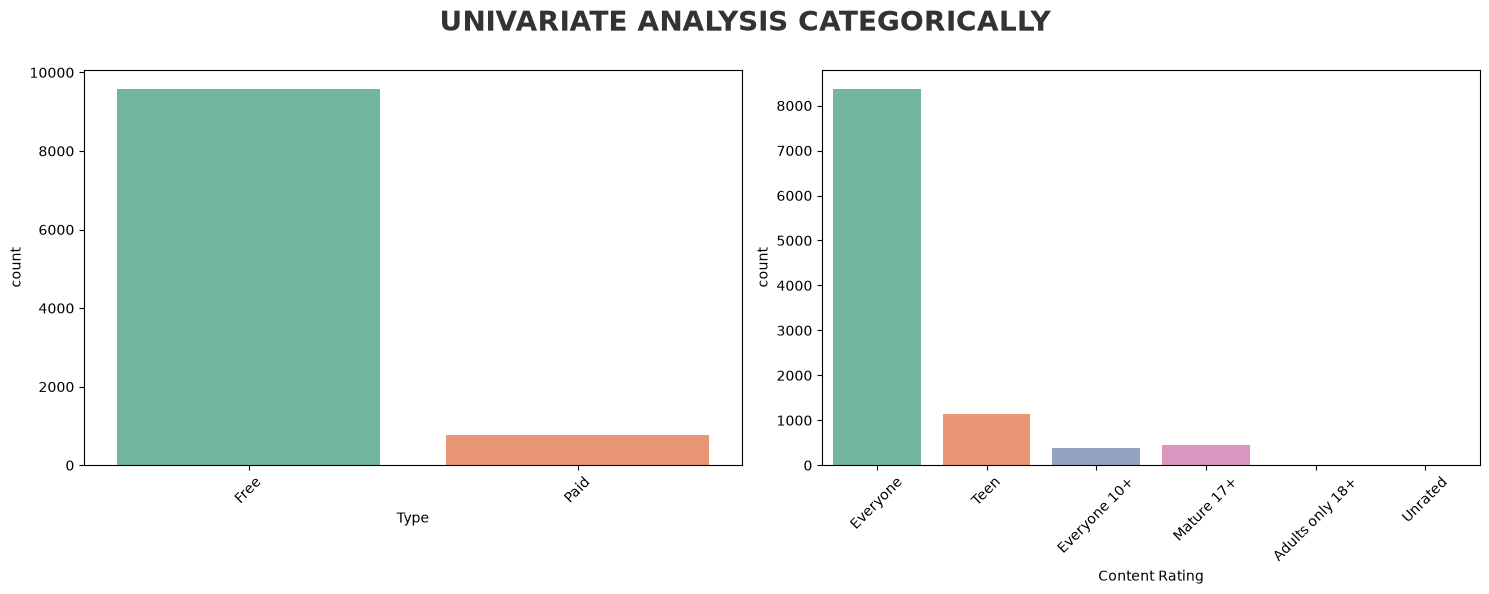

In [176]:
## COUNTPLOTS FOR CATEGORICAL EXPLORATORY ANALYSIS

plt.figure(figsize=(15,10))
plt.suptitle("UNIVARIATE ANALYSIS CATEGORICALLY", fontsize=20, fontweight='bold', alpha=0.8, y=1)

categorical_an = ['Type','Content Rating']
for i in range(0, len(categorical_an)):
    plt.subplot(2,2,i+1)
    sns.countplot(x=df_copy[categorical_an[i]], palette='Set2')
    plt.xlabel(categorical_an[i])
    plt.xticks(rotation=45)
    plt.tight_layout()

## OBSERVATIONS
Majority of apps preferred are free

## WHICH IS THE MOST POPULAR APP CATEGORY

<Axes: >

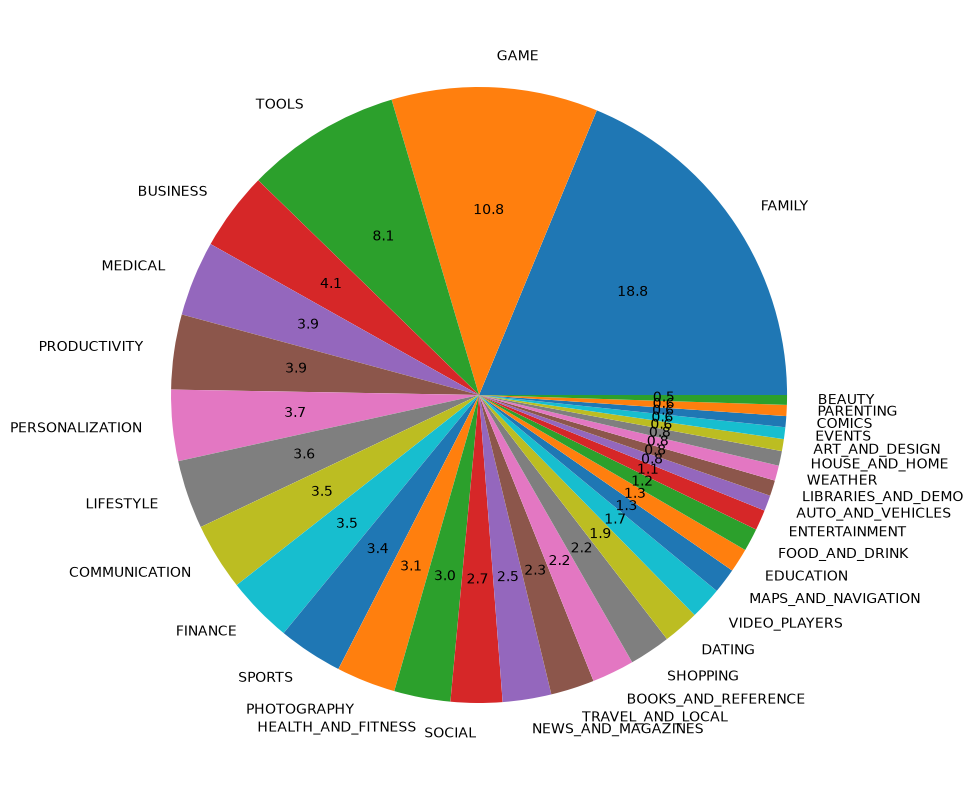

In [181]:
df_copy['Category'].value_counts().plot.pie(y=df_copy['Category'], figsize=(10,10), autopct='%1.1f')

## TOP 10 IN CATEGORY?

In [190]:
top_10 = (df_copy['Category'].value_counts(normalize=True)*100).head(10)

In [191]:
print(top_10)

Category
FAMILY             18.756036
GAME               10.826734
TOOLS               8.141781
BUSINESS            4.124010
MEDICAL             3.940506
PRODUCTIVITY        3.930848
PERSONALIZATION     3.728028
LIFESTYLE           3.602472
COMMUNICATION       3.534866
FINANCE             3.476917
Name: proportion, dtype: float64


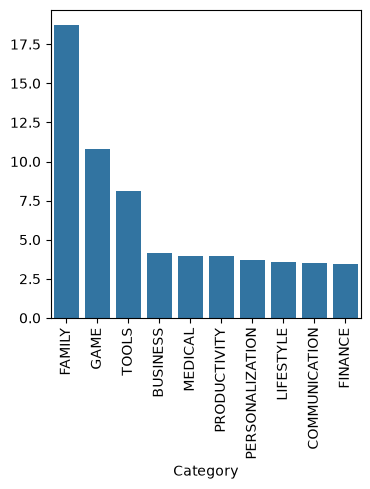

In [193]:
plt.figure(figsize=(4,4))
sns.barplot(x=top_10.index, y =top_10.values)
plt.xticks(rotation=90)
plt.show()

## INSIGHTS
Family has 18% of total apps, followed by Games with 10%.
Least popular apps category are Finance and Communication.

# WHICH ARE THE TOP 5 MOST INSTALLED APPS IN POPULAR CATEGORY?

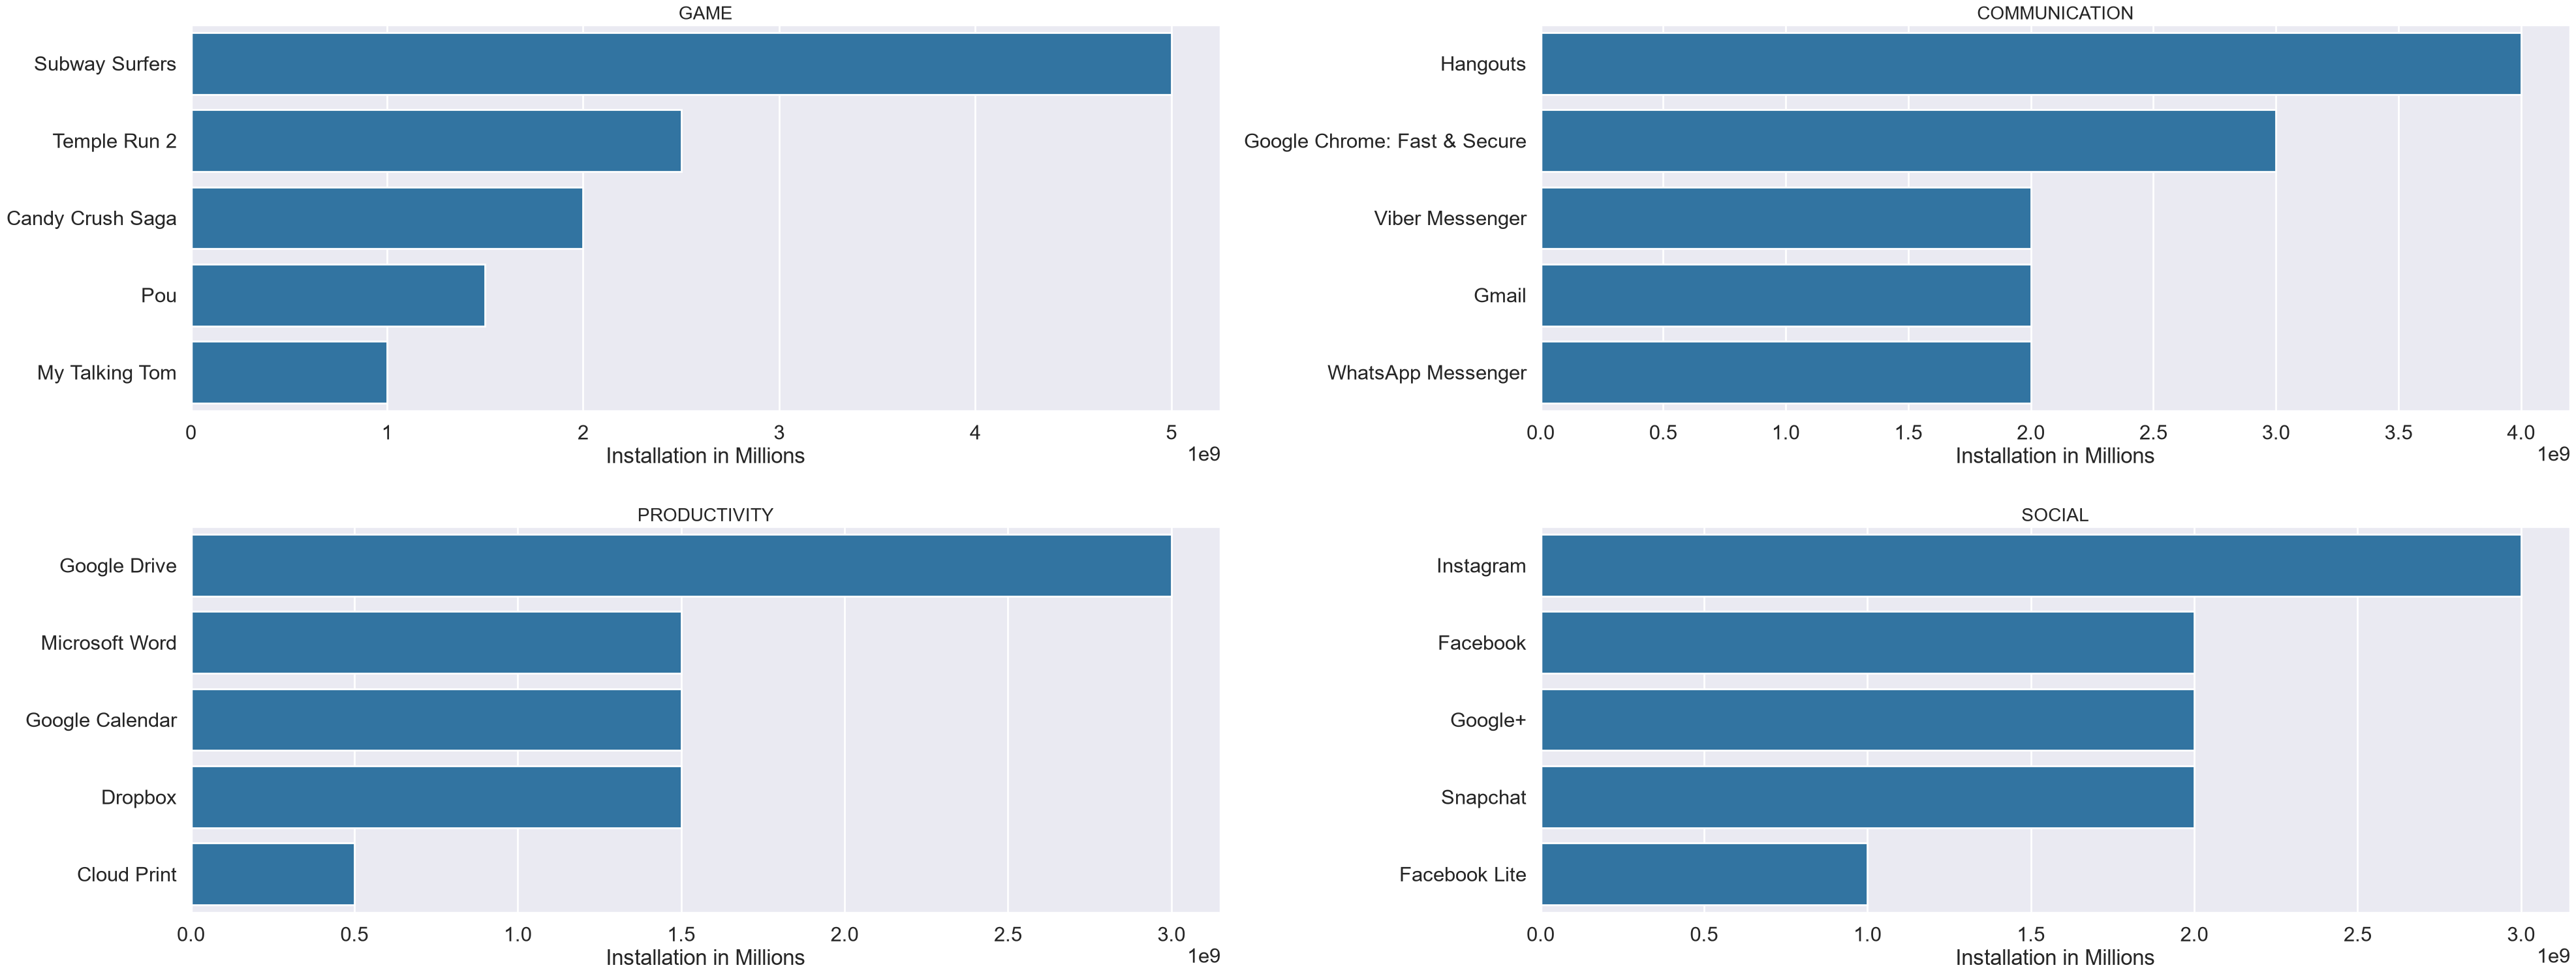

In [235]:
dfa = df_copy.groupby(['Category' ,'App'])['Installs'].sum().reset_index()
dfa = dfa.sort_values('Installs', ascending = False)
apps = ['GAME', 'COMMUNICATION', 'PRODUCTIVITY', 'SOCIAL' ]
sns.set_context("poster")
sns.set_style("darkgrid")


plt.figure(figsize=(40,30))


for i,app in enumerate(apps):
    df2 = dfa[dfa.Category == app]
    df3 = df2.head(5)
    plt.subplot(4,2,i+1)
    sns.barplot(data= df3,x= 'Installs' ,y='App' )
    plt.xlabel('Installation in Millions')
    plt.ylabel('')
    plt.title(app,size = 20)
    
plt.tight_layout()
plt.subplots_adjust(hspace= .3)
plt.show()